Ячейка 1: Импорты и проверка файла

In [3]:
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import pickle
import time
import os
import numpy as np

# Укажи точное имя твоего исходного файла
full_csv_path = '../data/raw/source.csv' # замени на свое, если отличается
chunk_size = 1_000_000 # Читаем по 1 миллиону строк за раз (оптимально для 3 ГБ)

csv_size = os.path.getsize(full_csv_path) / (1024 * 1024)
print(f"Объем исходного CSV: {csv_size:.2f} МБ")

Объем исходного CSV: 2974.69 МБ


Ячейка 2: Функция для замера времени

In [10]:
def measure_time(func, *args, repeats=3, **kwargs):
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        func(*args, **kwargs)
        end = time.perf_counter()
        times.append(end - start)
    return np.median(times)

Ячейка 3: Конвертация в Pickle (порциями)

In [11]:
pickle_path = '../data/interim/full_data.pkl'

print("Начинаем конвертацию в Pickle (это займет время)...")
start_time = time.perf_counter()

# Открываем файл для записи
with open(pickle_path, 'wb') as f:
    # Читаем CSV чанками (кусками)
    for chunk in pd.read_csv(full_csv_path, chunksize=chunk_size, low_memory=False):
        pickle.dump(chunk, f) # Записываем кусок

pickle_write_time = time.perf_counter() - start_time
pickle_size = os.path.getsize(pickle_path) / (1024 * 1024)
print(f"Pickle готов! Запись: {pickle_write_time:.2f} с, Объем: {pickle_size:.2f} МБ")

Начинаем конвертацию в Pickle (это займет время)...
Pickle готов! Запись: 20.41 с, Объем: 3287.25 МБ


Ячейка 4: Конвертация в Parquet (порциями через PyArrow)

In [12]:
parquet_path = '../data/interim/full_data.parquet'

print("Начинаем конвертацию в Parquet (это займет время)...")
start_time = time.perf_counter()

parquet_writer = None
for chunk in pd.read_csv(full_csv_path, chunksize=chunk_size, low_memory=False):
    # Переводим кусок Pandas в формат Arrow
    table = pa.Table.from_pandas(chunk)
    
    if parquet_writer is None:
        # При первом куске создаем файл
        parquet_writer = pq.ParquetWriter(parquet_path, table.schema)
    
    # Записываем кусок
    parquet_writer.write_table(table)

parquet_writer.close()

parquet_write_time = time.perf_counter() - start_time
parquet_size = os.path.getsize(parquet_path) / (1024 * 1024)
print(f"Parquet готов! Запись: {parquet_write_time:.2f} с, Объем: {parquet_size:.2f} МБ")

Начинаем конвертацию в Parquet (это займет время)...
Parquet готов! Запись: 28.73 с, Объем: 1086.44 МБ


Ячейка 5: Конвертация в Feather

In [13]:
feather_path = '../data/interim/full_data.feather'

print("Начинаем конвертацию в Feather...")
start_time = time.perf_counter()

# Читаем Parquet (он уже быстрый) и сохраняем в Feather
df_parquet = pd.read_parquet(parquet_path)
df_parquet.to_feather(feather_path)

feather_write_time = time.perf_counter() - start_time
feather_size = os.path.getsize(feather_path) / (1024 * 1024)
print(f"Feather готов! Запись: {feather_write_time:.2f} с, Объем: {feather_size:.2f} МБ")

Начинаем конвертацию в Feather...
Feather готов! Запись: 6.81 с, Объем: 1629.02 МБ


Ячейка 6: Замеры скорости чтения


In [14]:
print("Замеряем скорость чтения...")

# Чтение Pickle
pickle_read_time = measure_time(pd.read_pickle, pickle_path)
print(f"Pickle: Чтение {pickle_read_time:.2f} с")

# Чтение Parquet
parquet_read_time = measure_time(pd.read_parquet, parquet_path)
print(f"Parquet: Чтение {parquet_read_time:.2f} с")

# Чтение 3 столбцов из Parquet
cols_3 = ['aircraft_uid', 'origin', 'destination'] # Можно выбрать любые
parquet_3cols_read_time = measure_time(pd.read_parquet, parquet_path, columns=cols_3)
print(f"Parquet (3 столбца): Чтение {parquet_3cols_read_time:.2f} с")

# Чтение Feather
feather_read_time = measure_time(pd.read_feather, feather_path)
print(f"Feather: Чтение {feather_read_time:.2f} с")

Замеряем скорость чтения...


Pickle: Чтение 0.23 с
Parquet: Чтение 2.91 с
Parquet (3 столбца): Чтение 1.24 с
Feather: Чтение 2.52 с


Ячейка 7: Замер чтения CSV (для честного сравнения)

In [15]:
print("Замеряем чтение CSV порциями...")
start_time = time.perf_counter()

# Просто читаем и сразу удаляем куски из памяти
for chunk in pd.read_csv(full_csv_path, chunksize=chunk_size, low_memory=False):
    pass # ничего не делаем с куском, просто выбрасываем

csv_read_time = time.perf_counter() - start_time
print(f"CSV: Чтение порциями заняло {csv_read_time:.2f} с")

Замеряем чтение CSV порциями...
CSV: Чтение порциями заняло 14.96 с


Ячейка 8: Построение диаграммы

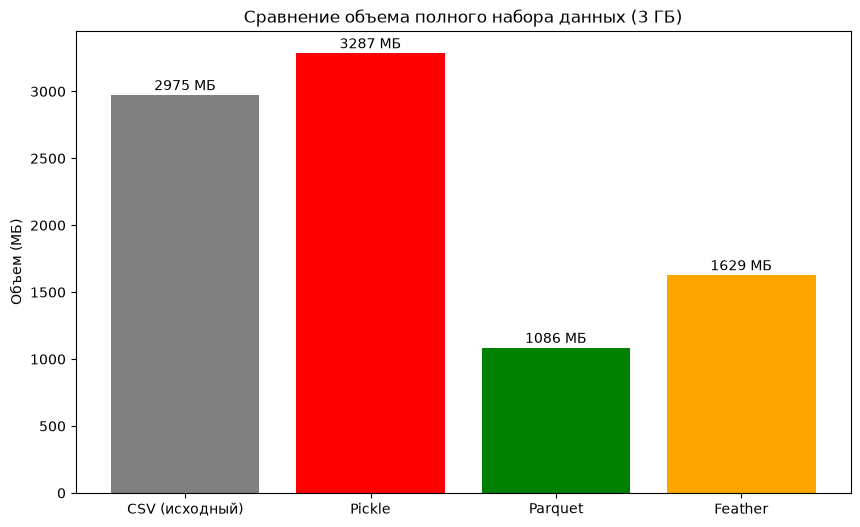

In [17]:
import matplotlib.pyplot as plt

formats = ['CSV (исходный)', 'Pickle', 'Parquet', 'Feather']
sizes = [csv_size, pickle_size, parquet_size, feather_size]
colors = ['gray', 'red', 'green', 'orange']

plt.figure(figsize=(10, 6))
bars = plt.bar(formats, sizes, color=colors)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 10, f'{yval:.0f} МБ', ha='center', va='bottom')

plt.title('Сравнение объема полного набора данных (3 ГБ)')
plt.ylabel('Объем (МБ)')
plt.show()

| Формат | Объём, МБ | Запись, с | Чтение, с | Отношение к CSV |
| :--- | :--- | :--- | :--- | :--- |
| CSV (исходный) | 2974.69 | — | 14.96 | 1.00 |
| Pickle | 3287.25 | 20.41 | 0.23 | 1.10 |
| Feather | 1629.02 | 6.81 | 2.52 | 0.55 |
| Parquet (snappy) | 1086.44 | 28.73 | 2.91 | 0.37 |
| Parquet, 3 столбца | — | — | 1.24 | — |

"В ходе эксперимента полный набор данных объемом почти 3 ГБ и насчитывающий 14 миллионов строк был сериализован в бинарные форматы. Для предотвращения переполнения оперативной памяти использовалось потоковое чтение с параметром chunksize.

Были получены следующие результаты:

Pickle показал наивысшую скорость чтения (0.23 с), однако объем файла превысил исходный CSV (3287 МБ), так как формат не использует сжатие и хранит служебные метаданные объектов Python.

Parquet (со сжатием Snappy) показал наилучшую степень сжатия — объем сократился почти в 3 раза по сравнению с CSV (до 1086 МБ), при этом скорость чтения выросла в 5 раз.

Feather занял промежуточное положение по объему, но показал отличную скорость записи (6.81 с).

Чтение трех отдельных столбцов из Parquet (1.24 с) оказалось быстрее чтения всего файла.

Итоговый выбор: Для дальнейшей работы выбран формат Parquet. Несмотря на то, что Pickle читается быстрее, он занимает слишком много места на диске и небезопасен. Parquet обеспечивает оптимальный баланс: он сжимает данные в 3 раза и читается в разы быстрее исходного CSV. Благодаря колоночному хранению, мы можем мгновенно загружать только нужные для анализа столбцы, не читая весь файл."